In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

I0000 00:00:1794129493.360657   25944 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794129512.489228   25944 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
tf.__version__

'2.21.0'

In [3]:
import pandas as pd
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
warnings.filterwarnings('ignore')
%matplotlib inline

In [4]:
Tv = '/home/islam-raad/Projects/Samsung_Innovation_Campus_2026/week-05-neural-networks/main/TV_Sales.csv'
df = pd.read_csv(Tv)
df = pd.get_dummies(df, columns=['shelve_loc', 'city', 'local'], drop_first=True)
X = df.drop(columns=['sales'])
y = df['sales']

In [5]:
df.head(5)

,sales,comp_price,income,price,shelve_loc_Good,shelve_loc_Medium,city_Yes,local_Yes
0,9.50,1932,73,1680,False,False,True,True
1,11.22,1554,48,1162,True,False,True,True
2,10.06,1582,35,1120,False,True,True,True
3,7.40,1638,100,1358,False,True,True,True
4,4.15,1974,64,1792,False,False,True,False


In [6]:
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)
n_vars = X_train.shape[1]

In [8]:
my_model1 = Sequential()
my_model1.add(Dense(input_dim=n_vars, units=1, activation="linear"))

E0000 00:00:1794129710.663161   25944 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [9]:
my_model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8 (32.00 B)

 Trainable params: 8 (32.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
n_epochs = 100
batch_size = 10
learn_rate = 0.002

In [11]:
my_optimizer=Adam(learning_rate=learn_rate)
my_model1.compile(loss="mae", optimizer=my_optimizer, metrics=["mse"])

In [12]:
my_summary = my_model1.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size,
                           validation_split=0.2, verbose=0)

In [13]:
my_summary.history.keys()

dict_keys(['loss', 'mse', 'val_loss', 'val_mse'])

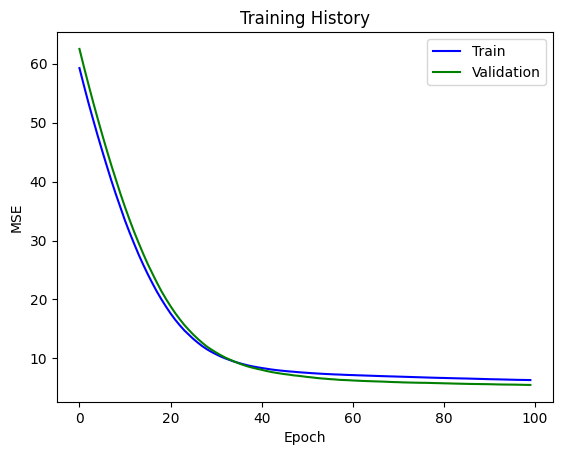

In [14]:
plt.plot(my_summary.history['mse'], c="b")
plt.plot(my_summary.history['val_mse'], c="g")
plt.title('Training History')
plt.ylabel('MSE')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

In [ ]:
y_pred = my_model1.predict(X_test)[:, 0]
RMSE = np.sqrt(np.mean((y_test-y_pred)**2))
np.round(RMSE, 3)

In [ ]:
MSE = my_model1.evaluate(X_test, y_test, verbose=0)[1]
RMSE = np.sqrt(MSE)
print("Test RMSE:", round(RMSE, 3))

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [ ]:
my_input = Input(shape=(n_vars,))
my_output = Dense(units=1, activation='linear')(my_input)

In [ ]:
my_model2 = Model(inputs=my_input, outputs=my_output)

In [ ]:
my_model2.summary()

In [ ]:
my_optimizer=Adam(learning_rate=learn_rate)
my_model2.compile(loss="mae", optimizer=my_optimizer, metrics=["mse"])

In [ ]:
my_summary = my_model2.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size,
                           validation_split=0.2, verbose=0)

In [ ]:
plt.plot(my_summary.history['mse'], c="b")
plt.plot(my_summary.history['val_mse'], c="g")
plt.title('Training History')
plt.ylabel('MSE')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

In [ ]:
MSE = my_model2.evaluate(X_test, y_test, verbose=0)[1]
RMSE = np.sqrt(MSE)
print("Test RMSE:", round(RMSE, 3))

In [ ]:
import os
import pandas as pd
import numpy as np
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.datasets import load_iris
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
%matplotlib inline

In [ ]:
data_raw = load_iris()
X = data_raw['data']
y0 = data_raw['target'].reshape(-1, 1)

In [ ]:
import tensorflow as tf

In [ ]:
y = tf.keras.utils.to_categorical(y0, num_classes=3)

In [ ]:
header = ['SepalLength', 'SepalWidth', 'PetalLength', 'PetalWidth', 'Species_0', 'Species_1', 'Species_2']
df = pd.DataFrame(np.concatenate([X, y], axis=1), columns=header)
df.head(5)

In [ ]:
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)
n_vars = X_train.shape[1]

In [ ]:
my_model = Sequential()
my_model.add(Dense(input_dim=n_vars, units=3, activation="softmax"))

In [ ]:
my_model.summary()

In [ ]:
n_epochs = 300
batch_size = 8
learn_rate = 0.005

In [ ]:
my_optimizer=Adam(learning_rate=learn_rate)
my_model.compile(loss="categorical_crossentropy", optimizer=my_optimizer, metrics=["accuracy"])

In [ ]:
my_summary = my_model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size,
                           validation_split=0.2, verbose=0)

In [ ]:
my_summary.history.keys()

In [ ]:
plt.plot(my_summary.history['accuracy'], c="b")
plt.plot(my_summary.history['val_accuracy'], c="g")
plt.title('Training History')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

In [ ]:
ACC = my_model.evaluate(X_test, y_test, verbose=0)[1]
print("Test Accuracy:", round(ACC, 3))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets.mnist import load_data
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Dropout, Flatten, MaxPooling2D

from tensorflow.keras.optimizers import Adam, RMSprop, SGD
warnings.filterwarnings('ignore')
%matplotlib inline

In [ ]:
(X_train, y_train), (X_test, y_test) = load_data()
n_train_size = X_train.shape[0]

In [ ]:
print("-" * 40)
print("Training data X shape:", X_train.shape)
print("Training data y shape:", y_train.shape)
print("-" * 40)
print("Test data X shape:", X_test.shape)
print("Test data y shape:", y_test.shape)
print("-" * 40)

In [ ]:
i_image = 0
plt.imshow(X_train[i_image, :, :], cmap="Greys")
plt.show()

In [ ]:
X_train = X_train / 255
X_test = X_test / 255

In [ ]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

In [ ]:
y = np.concatenate([y_train, y_test], axis=0)
y = tf.keras.utils.to_categorical(y, 10)
y_train = y[:n_train_size, :]
y_test = y[n_train_size:, :]

In [ ]:
drop_prob = 0.5
my_model = Sequential()
# 1st convolution + pooling.
my_model.add(Conv2D(input_shape=(28, 28, 1), filters=32, kernel_size=(5, 5), padding='same', activation='relu'))
my_model.add(MaxPooling2D(pool_size=2))
# 2nd convolution + pooling.
my_model.add(Conv2D(filters=64, kernel_size=(5, 5), padding='same', activation='relu'))
my_model.add(MaxPooling2D(pool_size=2))
# Flattened fully connected layer.
my_model.add(Flatten())
my_model.add(Dense(units=1024, activation='relu'))
# Apply dropout. 
my_model.add(Dropout(rate=drop_prob))
# Output layer.
my_model.add(Dense(units=10, activation='softmax'))

In [ ]:
my_model.summary()

In [ ]:
n_epochs = 10
batch_size = 64
learn_rate = 0.001

In [ ]:
my_optimizer=Adam(learning_rate=learn_rate)
my_model.compile(loss="categorical_crossentropy", optimizer=my_optimizer, metrics=["accuracy"])

In [ ]:
my_summary = my_model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size, validation_split=0.2, verbose=1)

In [ ]:
plt.plot(my_summary.history['accuracy'], c="b")
plt.plot(my_summary.history['val_accuracy'], c="g")
plt.title('Training History')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

In [ ]:
ACC = my_model.evaluate(X_test, y_test, verbose=0)[1]
print("Test Accuracy:", round(ACC, 3))

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets.cifar10 import load_data
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Dropout, Flatten, MaxPooling2D

from tensorflow.keras.optimizers import Adam, RMSprop, SGD
warnings.filterwarnings('ignore')
%matplotlib inline

In [ ]:
(X_train, y_train), (X_test, y_test) = load_data()
n_train_size = X_train.shape[0]

In [ ]:
print("-" * 40)
print("Training data X shape:", X_train.shape)
print("Training data y shape:", y_train.shape)
print("-" * 40)
print("Test data X shape:", X_test.shape)
print("Test data y shape:", y_test.shape)
print("-" * 40)

In [ ]:
i_image = 123
plt.imshow(X_train[i_image, :, :])
plt.show()

In [ ]:
X_train = X_train / 255
X_test = X_test / 255

In [ ]:
X_train = X_train.reshape(-1, 32, 32, 3)
X_test = X_test.reshape(-1, 32, 32, 3)

In [ ]:
y = np.concatenate([y_train, y_test], axis=0)
y = tf.keras.utils.to_categorical(y, 10)
y_train = y[:n_train_size, :]
y_test = y[n_train_size:, :]

In [ ]:
drop_prob = 0.7
my_model = Sequential()
# 1st convolution + pooling.
my_model.add(Conv2D(input_shape=(32,32,3), filters=32, kernel_size=(5, 5), padding='same', activation='relu'))
my_model.add(MaxPooling2D(pool_size=2))
# 2nd convolution + pooling.
my_model.add(Conv2D(filters=64, kernel_size=(5, 5), padding='same', activation='relu'))
my_model.add(MaxPooling2D(pool_size=2))
# Flattened fully connected layer.
my_model.add(Flatten())
my_model.add(Dense(units=1024, activation='relu'))
# Apply dropout.
my_model.add(Dropout(rate=drop_prob))
# Output layer.
my_model.add(Dense(units=10, activation='softmax'))

In [ ]:
my_model.summary()

In [ ]:
n_epochs = 10
batch_size = 128
learn_rate = 0.0001

In [ ]:
my_optimizer=Adam(learning_rate=learn_rate)
my_model.compile(loss="categorical_crossentropy", optimizer=my_optimizer, metrics=["accuracy"])

In [ ]:
my_summary = my_model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size, validation_split=0.3, verbose=1)

In [ ]:
plt.plot(my_summary.history['accuracy'], c="b")
plt.plot(my_summary.history['val_accuracy'], c="g")
plt.title('Training History')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

In [ ]:
ACC = my_model.evaluate(X_test, y_test, verbose=0)[1]
print("Test Accuracy:", round(ACC, 3))

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from statsmodels.tsa.api import ExponentialSmoothing
from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, TimeDistributed

from tensorflow.keras.optimizers import Adam, RMSprop, SGD
warnings.filterwarnings('ignore')
%matplotlib inline

In [ ]:
df = pd.read_csv('data_time_series.csv', header='infer', encoding='latin1')
n_times_steps = df.shape[0]
print(df.shape)

In [ ]:
df.head()

In [ ]:
plt.plot(df.Value, c="b", linewidth=2, linestyle="-")
plt.show()

In [ ]:
model = ExponentialSmoothing(df['Value'][0:40], seasonal='mul', seasonal_periods=6).fit()
pred = model.predict(start=0, end=50)
plt.plot(df, c='b', linewidth=2, linestyle='-', label='Data')
plt.plot(pred, c='r', linewidth=2, linestyle='--', label='Fit')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
scaler = MinMaxScaler()
ts_scaled = scaler.fit_transform(df)
plt.plot(ts_scaled, c="g", linewidth=2, linestyle="-")
plt.show()

In [ ]:
ts_scaled_2 = ts_scaled.reshape(1, -1, 1)

In [ ]:
n_epochs = 1001
batch_size = 1
learn_rate = 0.001

In [ ]:
n_input = 1
n_neurons = 100
n_output = 1

In [ ]:
my_model = Sequential()
my_model.add(SimpleRNN(units=n_neurons, return_sequences=True, input_shape=(None, n_input)))

my_model.add(TimeDistributed(Dense(units=n_output, activation="linear")))

In [ ]:
my_model.summary()

In [ ]:
my_optimizer=Adam(learning_rate=learn_rate)
my_model.compile(loss="mse", optimizer=my_optimizer, metrics=["mse"])

In [ ]:
my_summary = my_model.fit(ts_scaled_2[:, :-1, :], ts_scaled_2[:, 1:, :], epochs=n_epochs,
                          batch_size=batch_size, verbose=0)

In [ ]:
my_summary.history.keys()

In [ ]:
plt.plot(my_summary.history['mse'], c="b")
plt.title('Training History')
plt.ylabel('MSE')
plt.xlabel('Epoch')
plt.legend(['Train'], loc='upper right')
plt.show()

In [ ]:
n_ts_seed = 5
n_predict_time_steps = 55

In [ ]:
ts_seed = ts_scaled[0:n_ts_seed]
for i in range(n_predict_time_steps):
    X = ts_seed.reshape(1, -1, 1)
    y_pred = my_model.predict(X, verbose=0)
    y_last = y_pred[0, -1, 0]
    ts_seed = np.concatenate((ts_seed, np.array([y_last]).reshape(1, 1)), axis=0)

In [ ]:
ts = scaler.inverse_transform(ts_seed)
plt.plot(df.Value, c='b', linewidth=2, linestyle="-", label="Data")
plt.plot(ts, c='r', linewidth=2, linestyle="--", label="Fit")
plt.legend()
plt.tight_layout()
plt.savefig("out.png")
plt.show()